In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
washing_machine_map = {
    'House1': 'Appliance5', 
    'House2': 'Appliance2', 
    'House3': 'Appliance6', 
    'House5': 'Appliance3'  
}
clean_data_path = {
    'House1': r'D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House1.csv', 
    'House2': r'D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House2.csv', 
    'House3': r'D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House3.csv', 
    'House5': r'D:\Assessment\Flock Energy Assessment\cleaned_dataset\CLEAN_House5.csv'
}

In [3]:
house_data = {}
for house, wm_col in washing_machine_map.items():
    file_path = clean_data_path[house]
    df = pd.read_csv(file_path, index_col = 'Time', parse_dates = True)
    df = df.sort_index()
    df = df[['Aggregate', wm_col]].copy()
    df = df.resample('1min').mean()
    df = df.rename(columns = {wm_col: 'Washing_Machine'})
    df['hour_of_day'] = df.index.hour
    df['day_of_week'] = df.index.day_name()
    house_data[house] = df
    print(f"Null values in {house}")
    print(df.isnull().sum())
    print(f"Loaded {house} - mapped {wm_col} to Washing_Machine")

Null values in House1
Aggregate          116318
Washing_Machine    116318
hour_of_day             0
day_of_week             0
dtype: int64
Loaded House1 - mapped Appliance5 to Washing_Machine
Null values in House2
Aggregate          218914
Washing_Machine    218914
hour_of_day             0
day_of_week             0
dtype: int64
Loaded House2 - mapped Appliance2 to Washing_Machine
Null values in House3
Aggregate          100693
Washing_Machine    100693
hour_of_day             0
day_of_week             0
dtype: int64
Loaded House3 - mapped Appliance6 to Washing_Machine
Null values in House5
Aggregate          87220
Washing_Machine    87220
hour_of_day            0
day_of_week            0
dtype: int64
Loaded House5 - mapped Appliance3 to Washing_Machine


In [4]:
# ============================================================
# CONFIGURATION
# ============================================================

# Candidate thresholds to investigate
THRESHOLDS = [
    0.1,
    0.5,
    1,
    2,
    3,
    5,
    10,
    20,
    30,
    50,
    100
]


# ============================================================
# HELPER FUNCTION
# ============================================================

def calculate_threshold_metrics(power, threshold):
    """
    Calculate activity statistics for a given threshold.

    Missing values are excluded from active/inactive analysis.
    """

    # Only observed measurements
    observed = power.dropna()

    if len(observed) == 0:
        return None

    # Active = power >= threshold
    active = observed >= threshold

    active_minutes = active.sum()
    inactive_minutes = (~active).sum()

    active_pct = active.mean() * 100
    inactive_pct = 100 - active_pct

    # --------------------------------------------------------
    # Find continuous active runs
    # --------------------------------------------------------

    # Boolean Series indexed by timestamp
    active_series = active.copy()

    # Detect changes between active/inactive
    groups = (
        active_series != active_series.shift()
    ).cumsum()

    # Keep only active groups
    active_groups = active_series.groupby(groups)

    active_run_lengths = (
        active_groups.sum()
    )

    # Only groups that are actually active
    active_run_lengths = active_run_lengths[
        active_run_lengths > 0
    ]

    # --------------------------------------------------------
    # Run statistics
    # --------------------------------------------------------

    if len(active_run_lengths) > 0:

        number_of_runs = len(active_run_lengths)

        median_run = active_run_lengths.median()
        mean_run = active_run_lengths.mean()
        max_run = active_run_lengths.max()

        short_runs_1 = (
            active_run_lengths <= 1
        ).sum()

        short_runs_5 = (
            active_run_lengths <= 5
        ).sum()

        short_run_pct = (
            short_runs_5 / number_of_runs * 100
        )

    else:

        number_of_runs = 0
        median_run = 0
        mean_run = 0
        max_run = 0
        short_runs_1 = 0
        short_runs_5 = 0
        short_run_pct = 0


    return {
        'Threshold (W)': threshold,
        'Observed Minutes': len(observed),

        'Active Minutes': active_minutes,
        'Active %': active_pct,

        'Inactive Minutes': inactive_minutes,
        'Inactive %': inactive_pct,

        'Number of Active Runs': number_of_runs,

        'Median Active Run (min)': median_run,
        'Mean Active Run (min)': mean_run,
        'Longest Active Run (min)': max_run,

        '1-min Runs': short_runs_1,
        'Runs <=5 min': short_runs_5,
        'Short Run %': short_run_pct
    }


# ============================================================
# RUN ANALYSIS FOR ALL HOUSES
# ============================================================

all_threshold_results = []

for house, df in house_data.items():

    power = df['Washing_Machine']

    for threshold in THRESHOLDS:

        result = calculate_threshold_metrics(
            power,
            threshold
        )

        if result is not None:

            result['House'] = house

            all_threshold_results.append(result)


threshold_results = pd.DataFrame(
    all_threshold_results
)


# Put House first
cols = ['House'] + [
    col for col in threshold_results.columns
    if col != 'House'
]

threshold_results = threshold_results[cols]


# ============================================================
# DISPLAY RESULTS
# ============================================================

pd.set_option('display.max_columns', None)

threshold_results

,House,Threshold (W),Observed Minutes,Active Minutes,Active %,Inactive Minutes,Inactive %,Number of Active Runs,Median Active Run (min),Mean Active Run (min),Longest Active Run (min),1-min Runs,Runs <=5 min,Short Run %
0,House1,0.1,803773,19629,2.442107,784144,97.557893,1638,1.0,11.983516,177,993,1153,70.390720
1,House1,0.5,803773,18155,2.258722,785618,97.741278,642,34.0,28.278816,177,112,160,24.922118
2,House1,1.0,803773,17875,2.223887,785898,97.776113,603,34.0,29.643449,177,70,113,18.739635
3,House1,2.0,803773,17618,2.191912,786155,97.808088,589,34.0,29.911715,177,58,97,16.468591
4,House1,3.0,803773,17501,2.177356,786272,97.822644,582,33.0,30.070447,177,60,92,15.807560
5,House1,5.0,803773,17090,2.126222,786683,97.873778,646,33.0,26.455108,177,77,135,20.897833
6,House1,10.0,803773,16219,2.017858,787554,97.982142,1166,15.0,13.909949,177,76,272,23.327616
7,House1,20.0,803773,15125,1.881750,788648,98.118250,1761,8.0,8.588870,177,78,729,41.396934
8,House1,30.0,803773,14795,1.840694,788978,98.159306,1850,7.0,7.997297,176,78,862,46.594595
9,House1,50.0,803773,13950,1.735565,789823,98.264435,1988,5.0,7.017103,176,174,1048,52.716298


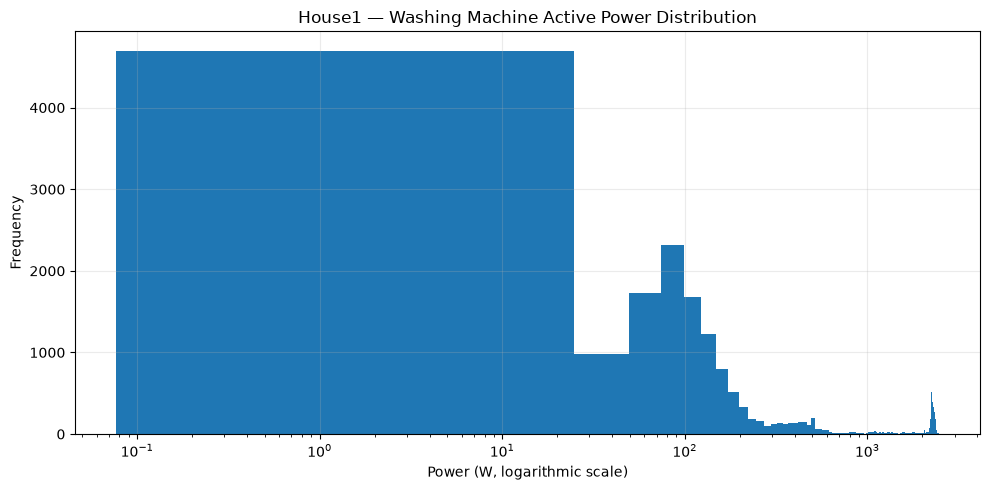

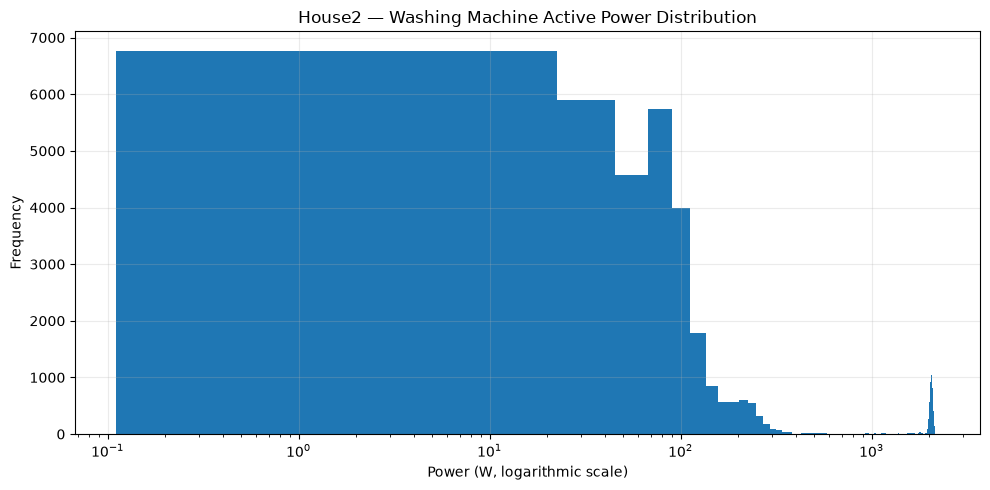

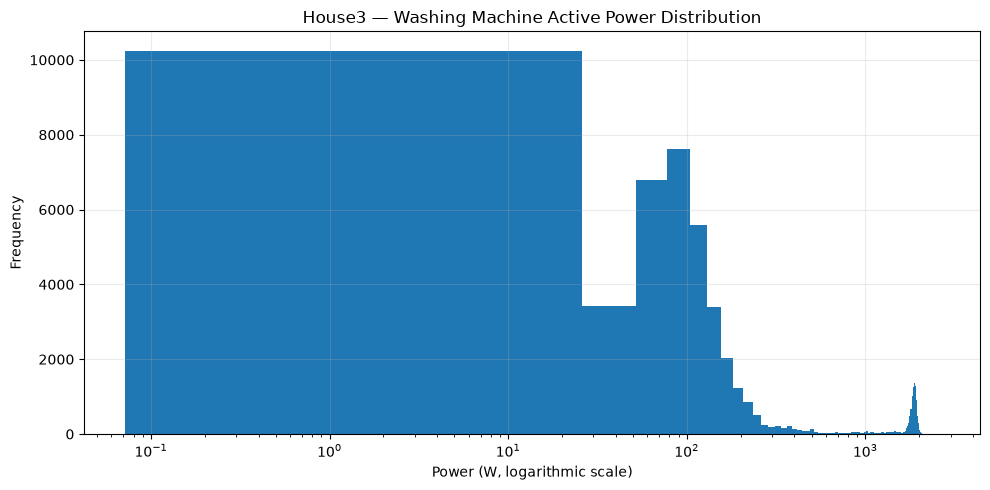

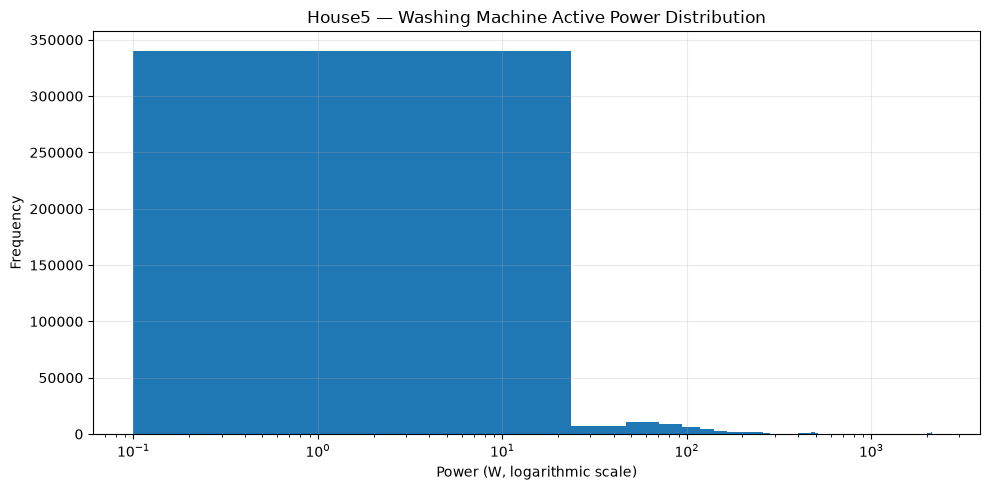

In [5]:
for house, df in house_data.items():

    power = df['Washing_Machine'].dropna()

    # Active measurements: power > 0
    active = power[power > 0]

    plt.figure(figsize=(10, 5))

    plt.hist(
        active,
        bins=100
    )

    plt.xscale('log')

    plt.title(f'{house} — Washing Machine Active Power Distribution')
    plt.xlabel('Power (W, logarithmic scale)')
    plt.ylabel('Frequency')

    plt.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

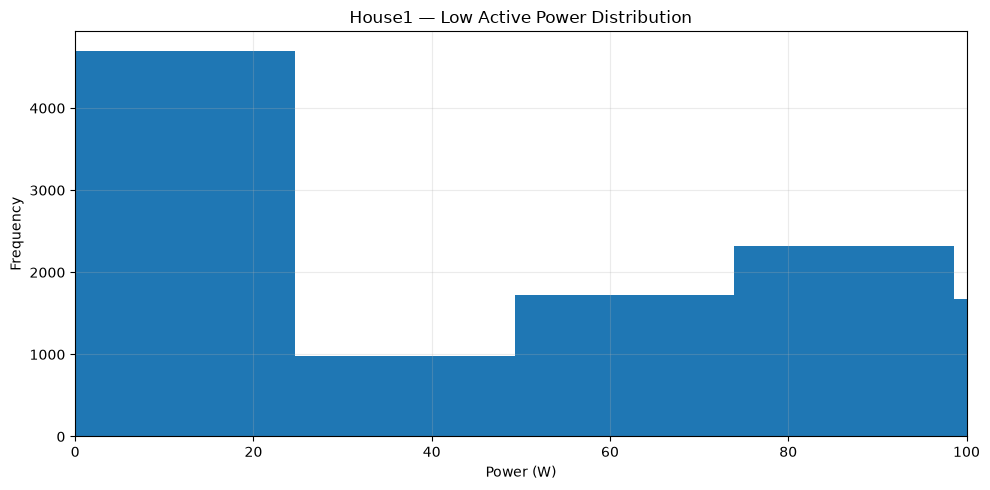

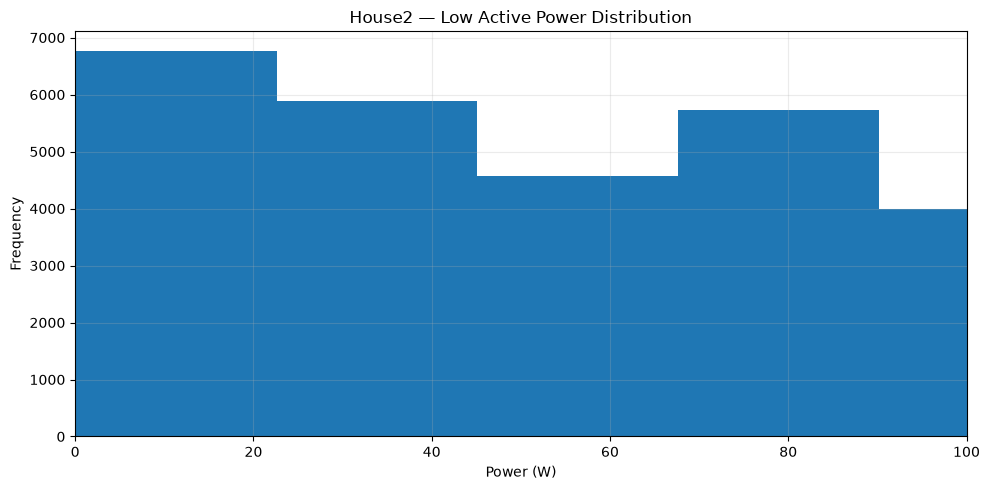

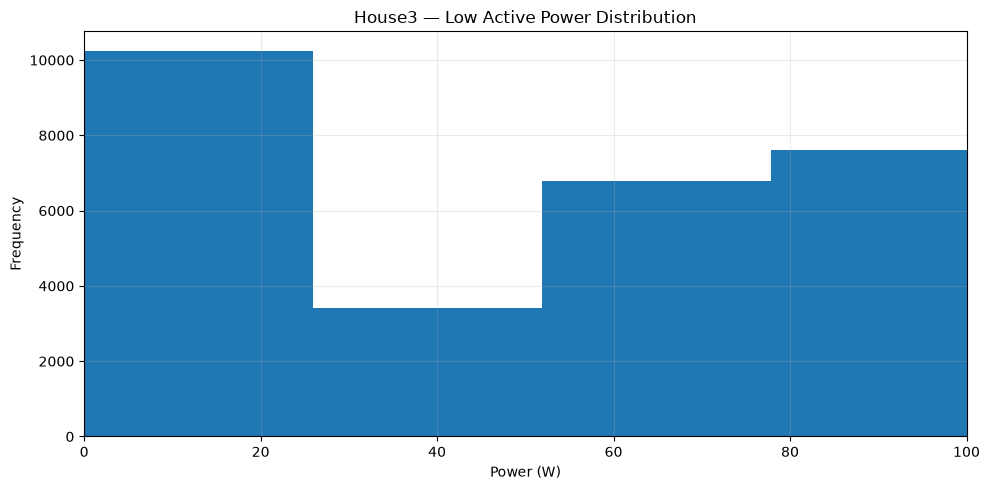

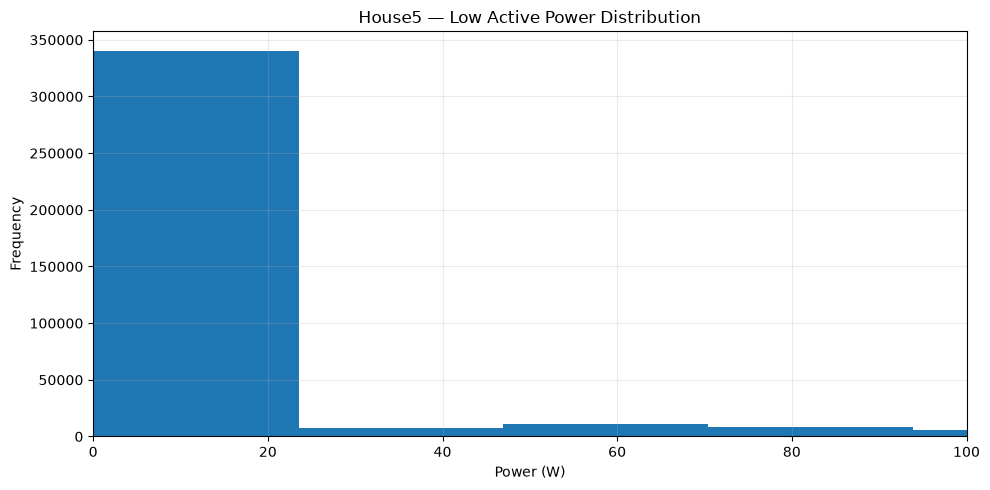

In [6]:
for house, df in house_data.items():

    active = df.loc[
        df['Washing_Machine'] > 0,
        'Washing_Machine'
    ]

    plt.figure(figsize=(10, 5))

    plt.hist(active, bins=100)

    plt.xlim(0, 100)

    plt.title(f'{house} — Low Active Power Distribution')
    plt.xlabel('Power (W)')
    plt.ylabel('Frequency')

    plt.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

* Threshold for active stage is 50 W

In [7]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

for house, df in house_data.items():
    
    total_minutes = len(df)
    
    # 1. Summarize Missing Intervals
    missing_minutes = df['Washing_Machine'].isnull().sum()
    missing_pct = (missing_minutes / total_minutes) * 100
    
    # 2. Summarize Zero/Off Time 
    zero_minutes = (df['Washing_Machine'] < 50).sum() 
    zero_pct = (zero_minutes / total_minutes) * 100
    
    # 3. ON time: > 0 W
    on_minutes = (df['Washing_Machine'] >= 50).sum()
    on_pct = (on_minutes / total_minutes) * 100
    
    # Date Range
    start_date = df.index.min()
    end_date = df.index.max()
    
    print(f"--- {house} Summary ---")
    print(f"Date Range: {start_date} to {end_date}")
    print(f"Missing Intervals: {missing_pct:.2f}% ({missing_minutes:,} mins)")
    print(f"Zero/Off Time: {zero_pct:.2f}% ({zero_minutes:,} mins)")
    print(f"ON Time: {on_pct:.2f}% ({on_minutes:,} mins)")
    

--- House1 Summary ---
Date Range: 2013-10-09 13:06:00 to 2015-07-10 11:56:00
Missing Intervals: 12.64% (116,318 mins)
Zero/Off Time: 85.84% (789,823 mins)
ON Time: 1.52% (13,950 mins)
--- House2 Summary ---
Date Range: 2013-09-17 22:08:00 to 2015-05-28 08:05:00
Missing Intervals: 24.62% (218,914 mins)
Zero/Off Time: 72.68% (646,201 mins)
ON Time: 2.70% (23,963 mins)
--- House3 Summary ---
Date Range: 2013-09-25 19:21:00 to 2015-06-02 10:55:00
Missing Intervals: 11.38% (100,693 mins)
Zero/Off Time: 84.02% (743,667 mins)
ON Time: 4.60% (40,735 mins)
--- House5 Summary ---
Date Range: 2013-09-26 09:56:00 to 2015-07-06 17:48:00
Missing Intervals: 9.34% (87,220 mins)
Zero/Off Time: 84.65% (790,256 mins)
ON Time: 6.01% (56,117 mins)


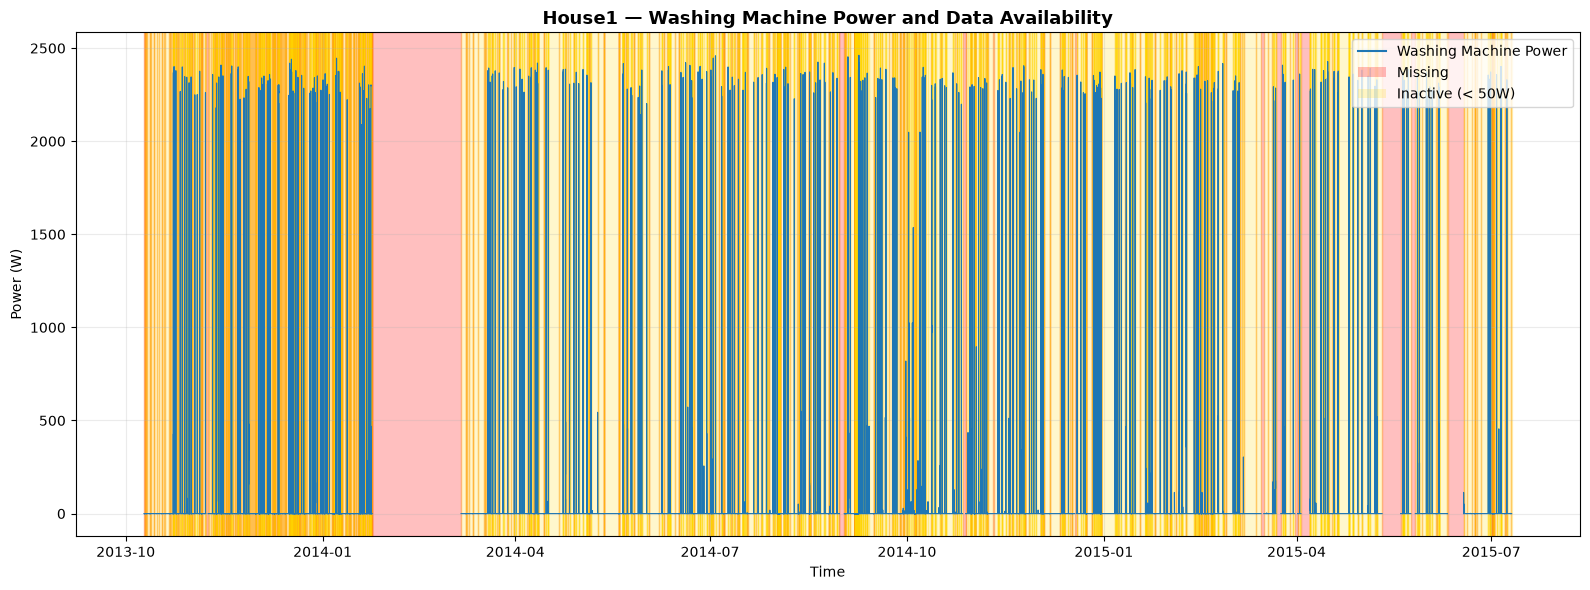

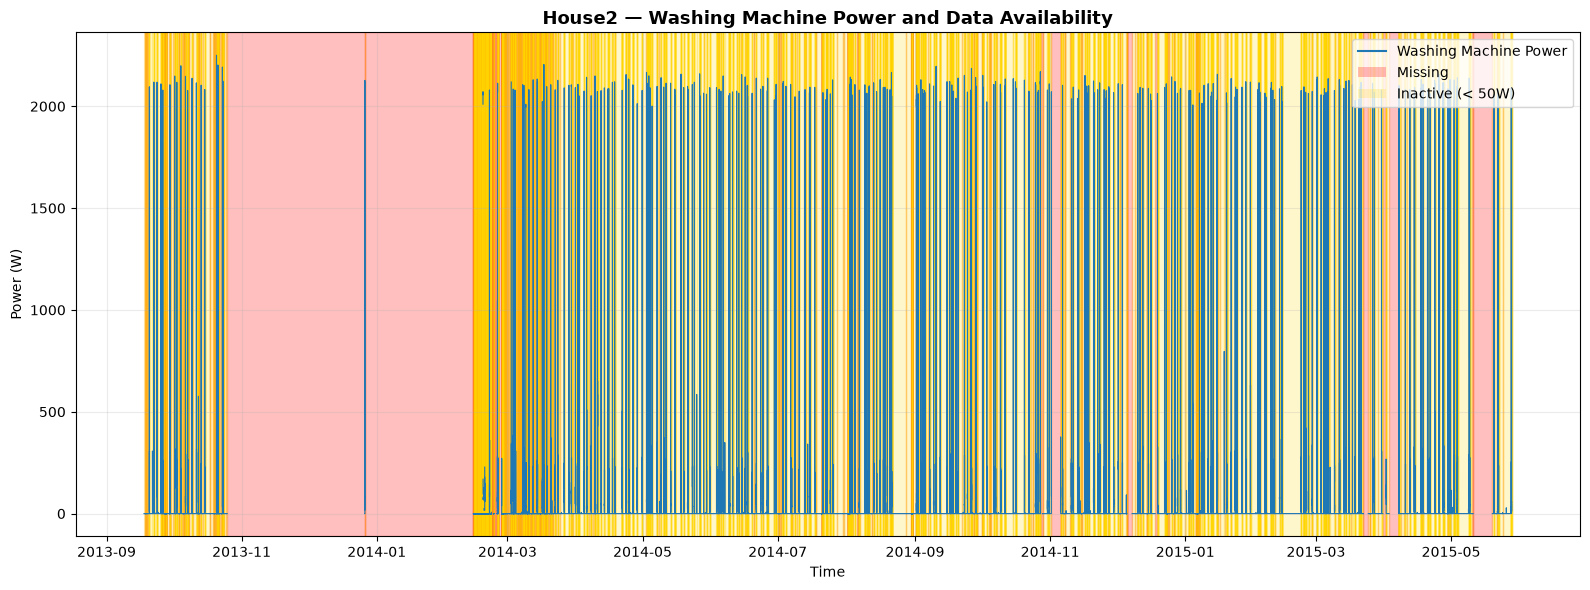

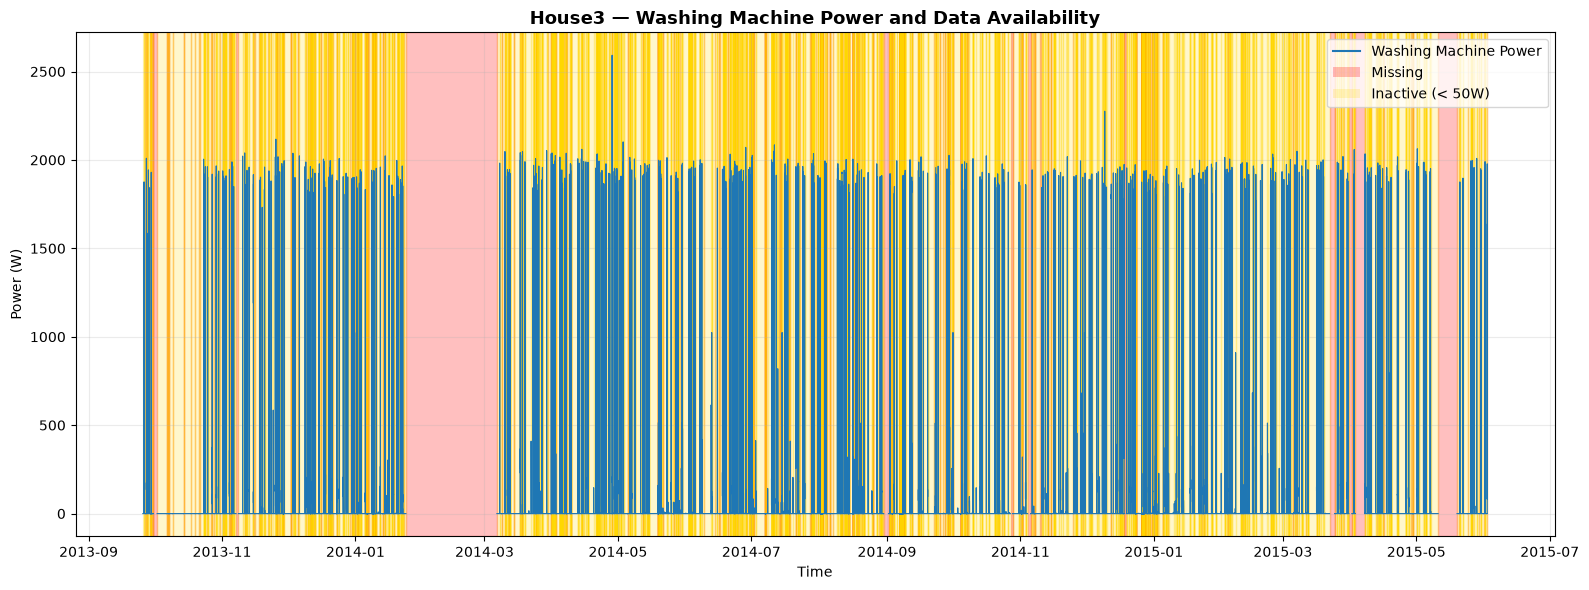

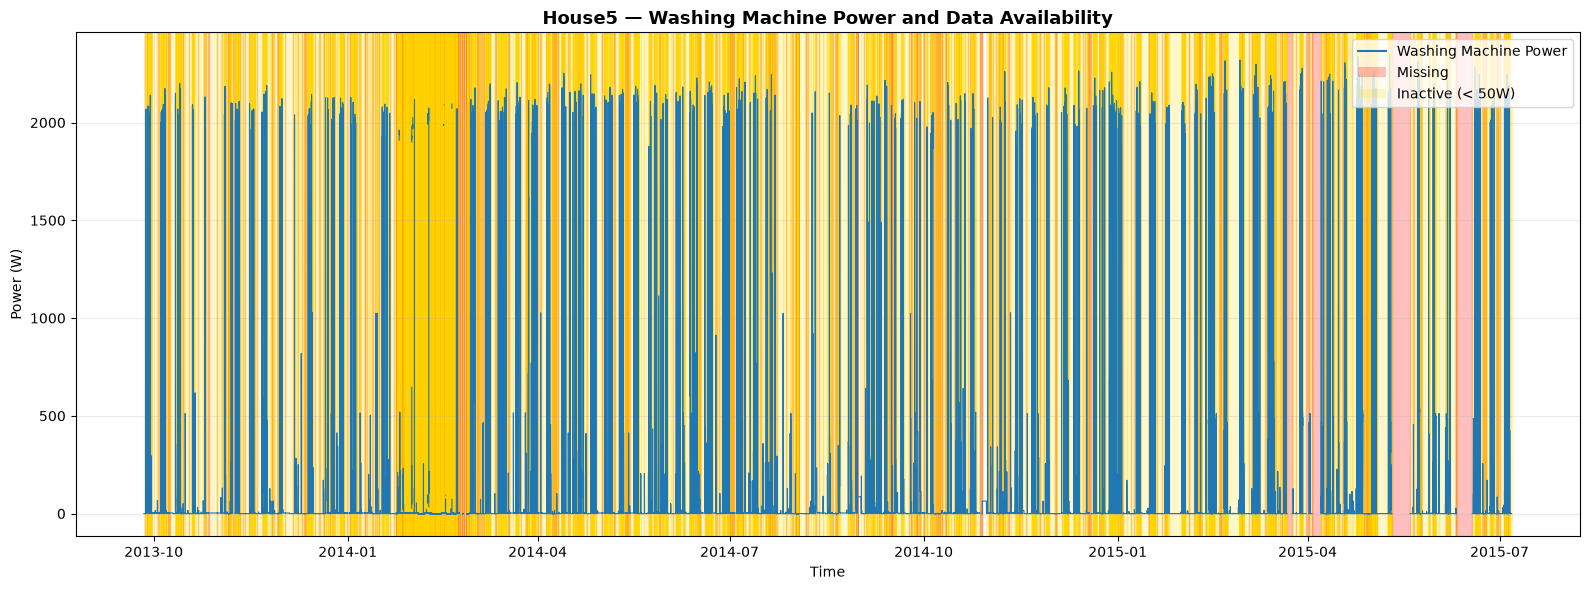

In [8]:
for house, df in house_data.items():

    # ============================================================
    # 1. Define the three mutually exclusive states
    # ============================================================

    # Missing measurement
    is_missing = df['Washing_Machine'].isna()

    # Inactive: measured value exists but power is below 50 W
    is_off = (
        df['Washing_Machine'].notna() &
        (df['Washing_Machine'] < 50)
    )

    # Active: measured value exists and power is >= 50 W
    is_active = (
        df['Washing_Machine'].notna() &
        (df['Washing_Machine'] >= 50)
    )


    # ============================================================
    # 2. Function to find continuous True periods
    # ============================================================

    def get_periods(mask):
        """
        Return start and end timestamps for every continuous
        True period in a Boolean Series.
        """

        # Identify changes between True and False
        groups = (mask != mask.shift()).cumsum()

        # Get first and last timestamp of every group
        periods = (
            df.index.to_series()
            .groupby(groups)
            .agg(['first', 'last'])
        )

        # Keep only groups where the state is True
        true_groups = mask.groupby(groups).first()
        periods = periods[true_groups]

        return periods


    # ============================================================
    # 3. Find continuous missing and inactive periods
    # ============================================================

    missing_periods = get_periods(is_missing)
    off_periods = get_periods(is_off)


    # ============================================================
    # 4. Create plot
    # ============================================================

    fig, ax = plt.subplots(figsize=(16, 6))


    # ============================================================
    # 5. Plot washing-machine power
    # ============================================================

    ax.plot(
        df.index,
        df['Washing_Machine'],
        linewidth=0.8,
        label='Washing Machine Power'
    )


    # ============================================================
    # 6. Shade missing periods → RED
    # ============================================================

    for _, period in missing_periods.iterrows():

        ax.axvspan(
            period['first'],
            period['last'],
            color='red',
            alpha=0.25
        )


    # ============================================================
    # 7. Shade inactive periods → YELLOW
    # ============================================================

    for _, period in off_periods.iterrows():

        ax.axvspan(
            period['first'],
            period['last'],
            color='gold',
            alpha=0.20
        )


    # ============================================================
    # 8. Create clean legend
    # ============================================================

    legend_elements = [

        Line2D(
            [0],
            [0],
            label='Washing Machine Power'
        ),

        Patch(
            facecolor='red',
            alpha=0.25,
            label='Missing'
        ),

        Patch(
            facecolor='gold',
            alpha=0.20,
            label='Inactive (< 50W)'
        )
    ]


    ax.legend(
        handles=legend_elements,
        loc='upper right'
    )


    # ============================================================
    # 9. Labels and formatting
    # ============================================================

    ax.set_title(
        f'{house} — Washing Machine Power and Data Availability',
        fontsize=13,
        fontweight='bold'
    )

    ax.set_xlabel('Time')
    ax.set_ylabel('Power (W)')

    ax.grid(
        True,
        alpha=0.25
    )


    # ============================================================
    # 10. Display
    # ============================================================

    plt.tight_layout()
    plt.show()

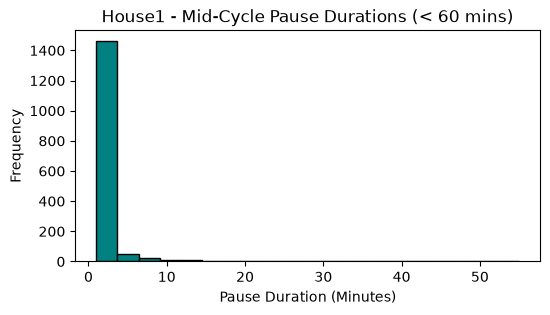

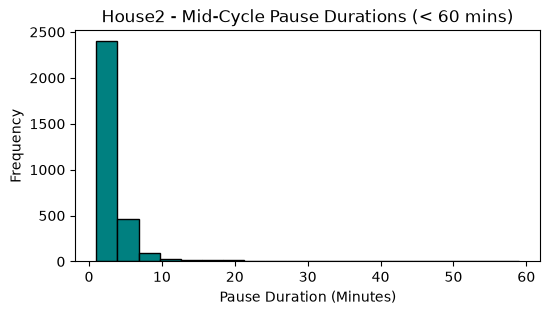

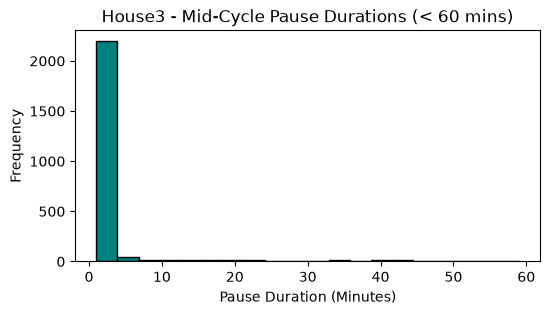

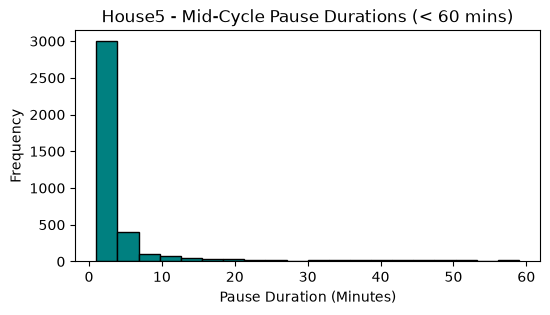

In [9]:
# Using the 50W threshold we proved with the data
threshold = 50 

for house, df in house_data.items():
    # Only look at valid, non-missing data for this gap analysis
    valid_data = df.dropna(subset=['Washing_Machine'])
    
    # Find where the machine drops below 50W
    is_inactive = valid_data['Washing_Machine'] < threshold
    
    # Group consecutive inactive minutes together
    inactive_groups = (is_inactive != is_inactive.shift()).cumsum()
    
    # Calculate the total length of each inactive gap
    gap_lengths = is_inactive.groupby(inactive_groups).sum()
    
    # Filter for short gaps (mid-cycle pauses usually aren't longer than 60 mins)
    intra_cycle_gaps = gap_lengths[(gap_lengths > 0) & (gap_lengths < 60)]
    
    # Plot it
    plt.figure(figsize=(6, 3))
    plt.hist(intra_cycle_gaps, bins=20, color='teal', edgecolor='black')
    plt.title(f"{house} - Mid-Cycle Pause Durations (< 60 mins)")
    plt.xlabel("Pause Duration (Minutes)")
    plt.ylabel("Frequency")
    plt.show()

* In a cycle, washing machine stops consuming power for 15 minutes or less.

In [13]:
power_threshold = 50
max_gap_minutes = 15

for house, df in house_data.items():
    # 1. Extract raw values (Missing stays NaN)
    power_vals = df['Washing_Machine'].values
    cycle_ids = np.zeros(len(power_vals), dtype=int)
    
    current_id = 0
    in_cycle = False
    last_active_idx = -1
    
    for i in range(len(power_vals)):
        val = power_vals[i]
        
        if np.isnan(val):
            in_cycle = False  # Hard break on missing data
            continue
            
        if val >= power_threshold:
            if not in_cycle:
                # Start a brand new cycle (NO BRIDGING)
                in_cycle = True
                current_id += 1
            else:
                # Continue existing cycle (BRIDGE THE GAP)
                if last_active_idx != -1 and (i - last_active_idx) > 1:
                    cycle_ids[last_active_idx + 1 : i] = current_id
                    
            # Tag the current active minute and update pointer
            cycle_ids[i] = current_id
            last_active_idx = i
            
        else:
            # val < power_threshold
            if in_cycle:
                # Terminate the cycle if the gap limit is exceeded
                gap_duration = i - last_active_idx
                if gap_duration > max_gap_minutes:
                    in_cycle = False
                    
    # Reattach clean IDs to dataframe
    df['Cycle_ID'] = cycle_ids
    
    # Diagnostics
    cycle_durations = df[df['Cycle_ID'] > 0].groupby('Cycle_ID').size()
    
    print(f"\n--- {house} Raw Grouping ---")
    if len(cycle_durations) > 0:
        print(f"Total Raw Cycles: {len(cycle_durations)}")
        print(f"Max True Duration: {cycle_durations.max()} mins")


--- House1 Raw Grouping ---
Total Raw Cycles: 450
Max True Duration: 249 mins

--- House2 Raw Grouping ---
Total Raw Cycles: 406
Max True Duration: 215 mins

--- House3 Raw Grouping ---
Total Raw Cycles: 805
Max True Duration: 214 mins

--- House5 Raw Grouping ---
Total Raw Cycles: 1148
Max True Duration: 2866 mins


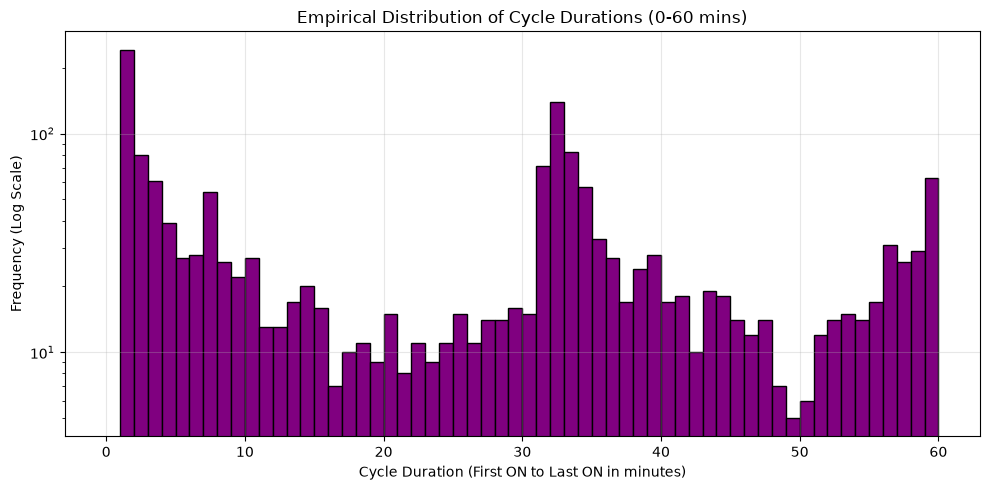

In [17]:
all_raw_durations = []

# Collect the exact true durations from all houses
for house, df in house_data.items():
    cycle_durations = df[df['Cycle_ID'] > 0].groupby('Cycle_ID').size()
    all_raw_durations.extend(cycle_durations.values)

# Plot the distribution zoomed in on the first 60 minutes
plt.figure(figsize=(10, 5))
plt.hist(all_raw_durations, bins=60, range=(0, 60), color='purple', edgecolor='black')
plt.title("Empirical Distribution of Cycle Durations (0-60 mins)")
plt.xlabel("Cycle Duration (First ON to Last ON in minutes)")
plt.ylabel("Frequency (Log Scale)")
plt.yscale('log')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

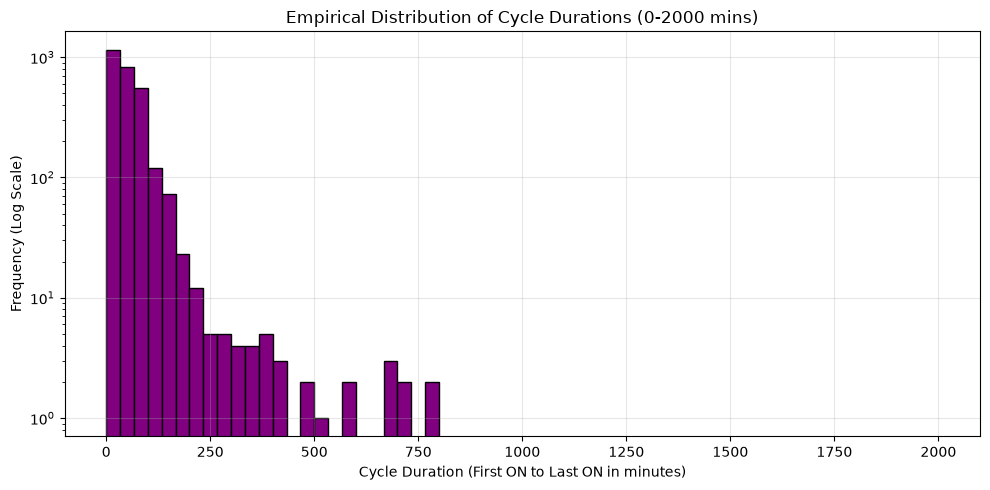

In [18]:
# Plot the distribution zoomed in on the first 2000 minutes
plt.figure(figsize=(10, 5))
plt.hist(all_raw_durations, bins=60, range=(0, 2000), color='purple', edgecolor='black')
plt.title("Empirical Distribution of Cycle Durations (0-2000 mins)")
plt.xlabel("Cycle Duration (First ON to Last ON in minutes)")
plt.ylabel("Frequency (Log Scale)")
plt.yscale('log')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

* We will take 20 minutes as threshold for min cycle duration. Because graph is bimodal and 20 has min after which it starts increasing again.

In [29]:
min_cycle_minutes = 20
cycle_metrics = []

for house, df in house_data.items():
    cycle_durations = df[df['Cycle_ID'] > 0].groupby('Cycle_ID').size()
    valid_ids = cycle_durations[cycle_durations >= min_cycle_minutes].index
    
    for cid in valid_ids:
        cycle_data = df[df['Cycle_ID'] == cid]
        start_time = cycle_data.index.min()
        
        cycle_metrics.append({
            'House': house,
            'Duration': len(cycle_data),
            'Start_Hour': start_time.hour,
            'Day_of_Week': start_time.day_name(),
            'Energy_kWh': cycle_data['Washing_Machine'].sum() / 60000.0
        })

metrics_df = pd.DataFrame(cycle_metrics)

C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_28296\2678645561.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=metrics_df, x='House', y='Duration', palette='viridis', showfliers=True)


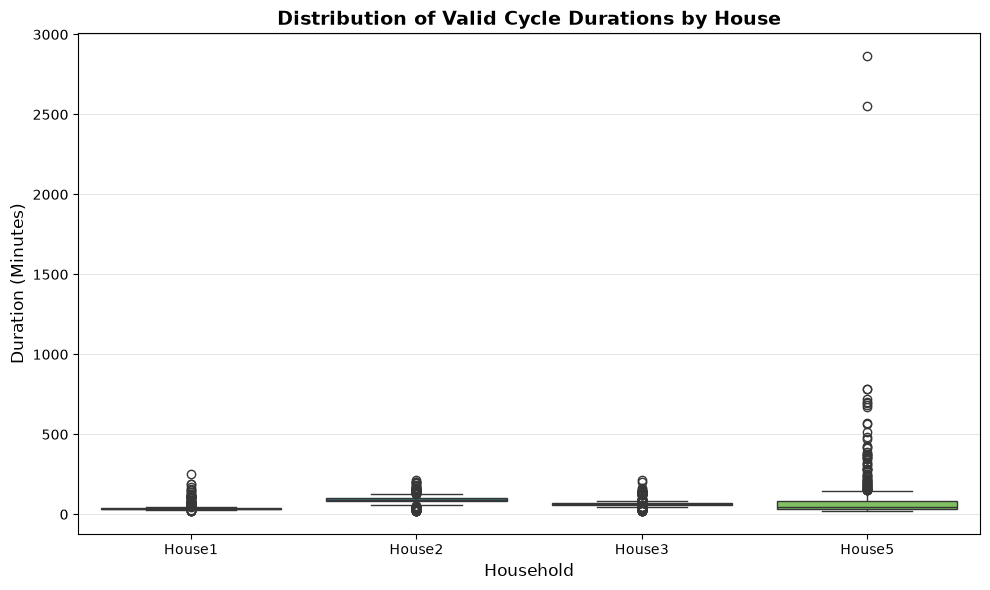

In [30]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=metrics_df, x='House', y='Duration', palette='viridis', showfliers=True)
plt.title('Distribution of Valid Cycle Durations by House', fontsize=14, fontweight='bold')
plt.ylabel('Duration (Minutes)', fontsize=12)
plt.xlabel('Household', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

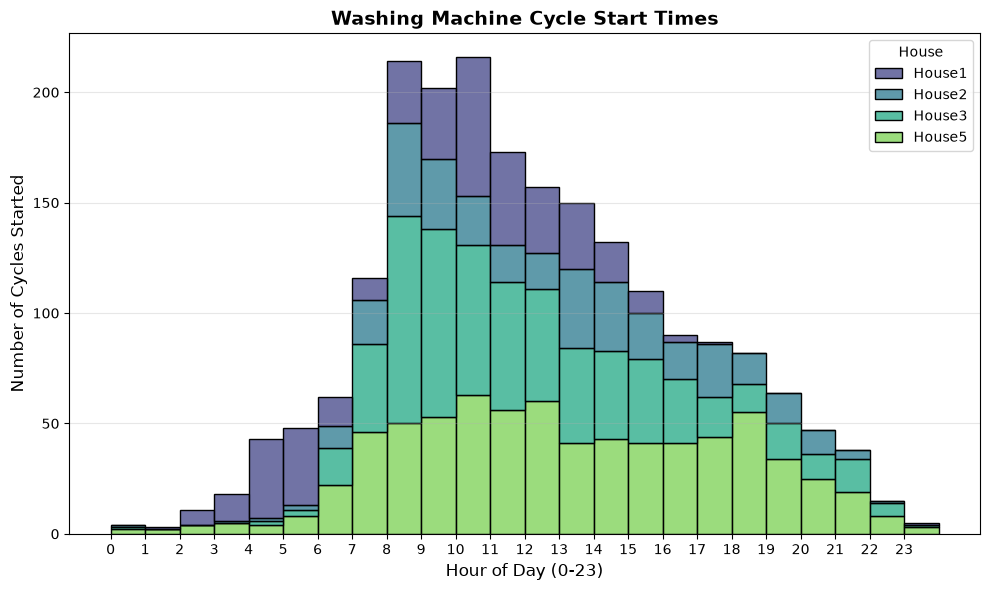

In [31]:
plt.figure(figsize=(10, 6))
sns.histplot(data=metrics_df, x='Start_Hour', hue='House', multiple='stack', 
             bins=24, binrange=(0,24), palette='viridis', edgecolor='black')
plt.title('Washing Machine Cycle Start Times', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (0-23)', fontsize=12)
plt.ylabel('Number of Cycles Started', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\Aditya Raj\AppData\Local\Temp\ipykernel_28296\62423576.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=metrics_df, x='House', y='Energy_kWh', palette='viridis', inner=None, alpha=0.6)


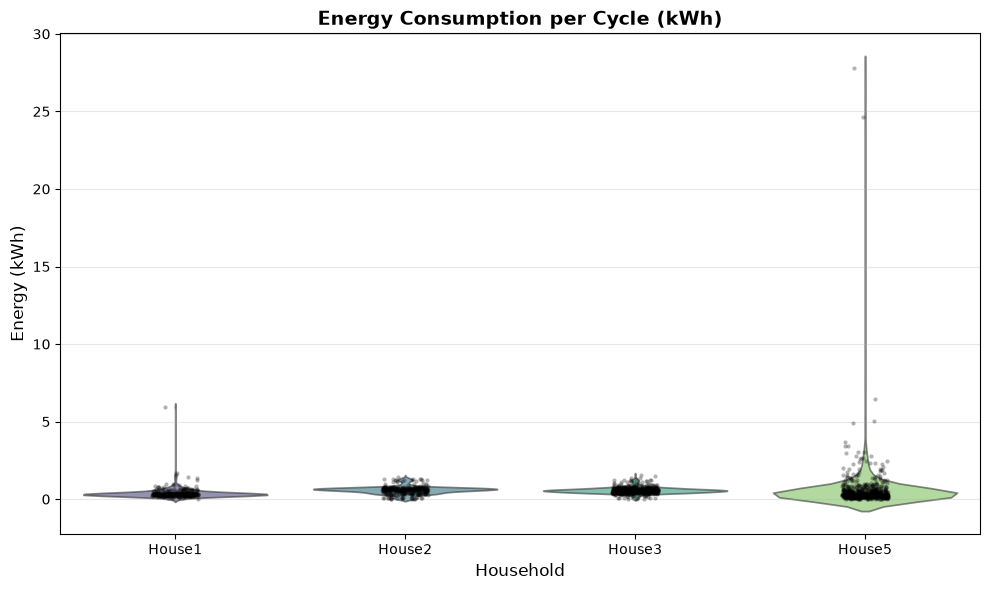

In [32]:
plt.figure(figsize=(10, 6))
# Using a violin plot combined with a swarm plot gives a beautiful view of energy distributions
sns.violinplot(data=metrics_df, x='House', y='Energy_kWh', palette='viridis', inner=None, alpha=0.6)
sns.stripplot(data=metrics_df, x='House', y='Energy_kWh', color='black', alpha=0.3, size=3)

plt.title('Energy Consumption per Cycle (kWh)', fontsize=14, fontweight='bold')
plt.ylabel('Energy (kWh)', fontsize=12)
plt.xlabel('Household', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Washing Machine Cycle Detection Rule**

An active washing machine cycle is identified using:

* **Active Power Threshold:** The appliance is considered in an active running state when power consumption strictly exceeds **50 Watts**.
* **Missing Data Hard-Break:** Missing sensor readings (`NaN`) are treated as unknown states. Cycles cannot bridge across missing data intervals.
* **Intra-Cycle Gap Bridging:** Mid-cycle power drops below 50 Watts (representing internal soaking, resting, or draining phases) are bridged and grouped into the current continuous cycle, provided the inactive gap does not exceed **15 minutes** before returning to an active state.
* **True Duration Measurement:** The total duration of a cycle is calculated strictly from the first active minute (> 50W) to the final active minute (> 50W). Trailing inactive gaps are stripped and do not inflate the cycle length.
* **Minimum Valid Duration (Noise Filter):** To eliminate transient sensor glitches and phantom spikes, any detected cycle with a true duration of less than **20 minutes** is classified as hardware noise and discarded.

In [33]:
# Print the final count of valid cycles per house
cycle_summary = metrics_df['House'].value_counts().sort_index().reset_index()
cycle_summary.columns = ['House', 'Total_Valid_Cycles']
print(cycle_summary)

    House  Total_Valid_Cycles
0  House1                 372
1  House2                 337
2  House3                 649
3  House5                 729


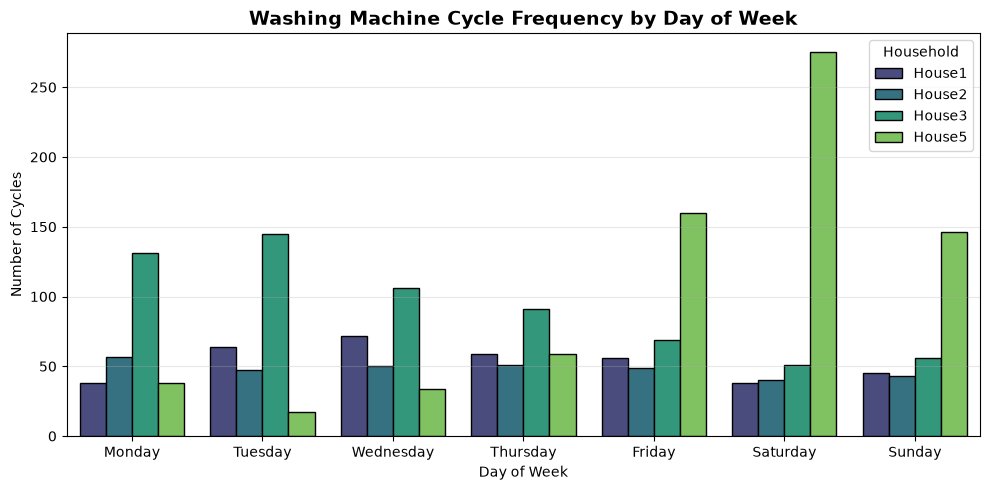

In [34]:
# Order the days logically for the plot
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(10, 5))
sns.countplot(data=metrics_df, x='Day_of_Week', hue='House', order=day_order, palette='viridis', edgecolor='black')
plt.title('Washing Machine Cycle Frequency by Day of Week', fontsize=14, fontweight='bold')
plt.ylabel('Number of Cycles')
plt.xlabel('Day of Week')
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Household')
plt.tight_layout()
plt.show()

### Usage Patterns: Hour of the Day

* **Observation:** Washing machine usage strictly follows a diurnal pattern tied to human waking hours. Activity is almost non-existent between midnight and 6 AM, surges rapidly in the early morning to a distinct peak between 8 AM and 12 PM, and then steadily declines throughout the afternoon and evening.


* **Conclusion Justification (Why we conclude this):** The strict absence of overnight activity mathematically validates the cycle detection rule. If the state machine were capturing random sensor noise or standby power glitches, the distribution would be flat or scattered across all 24 hours. The morning peak perfectly reflects real-world human behavior of starting chores at the beginning of the day.



### Usage Patterns: Day of the Week

* **Observation:** Household lifestyle routines dictate completely different weekly scheduling:


* **House 1 & House 2:** Exhibit relatively flat, consistent usage across the entire week with only minor fluctuations, indicating a routine of smaller, daily laundry loads.


* **House 3:** Shows a strong early-week bias, peaking on Monday and Tuesday before trailing off toward the weekend.


* **House 5:** Exhibits an extreme weekend-heavy profile. Usage is nearly zero from Monday through Wednesday, begins climbing on Friday, and culminates in a massive volume spike on Saturday and Sunday.




* **Conclusion Justification:** We can definitively conclude that House 5 "batches" their laundry for the weekend, likely due to weekday work/school constraints, whereas Houses 1 and 2 integrate the chore into their daily schedules.


### Cycle Characteristic Comparison: Duration and Energy per Cycle

* **Observation (House 1 - Rapid Modes):** House 1 relies almost exclusively on short wash cycles clustered under 60 minutes. Consequently, its energy footprint is the smallest, consistently drawing less than 1 kWh per cycle.


* **Observation (Houses 2 & 3 - Eco/Standard Modes):** Both homes show a tightly clustered median duration of 80 to 100 minutes per cycle. Their energy consumption is highly predictable, falling strictly between 0.5 and 2.0 kWh per load.


* **Observation (House 5 - Severe Anomalies):** While House 5's median duration matches House 2, it contains extreme outliers that stretch up to nearly 3,000 minutes (approx. 48 hours). These massive durations correlate with unprecedented energy spikes, drawing up to 30 kWh in a single continuous event.


* **Conclusion Justification:** We conclude that House 1 uses "Quick Wash" settings, while Houses 2 and 3 utilize longer, standard or "Eco" wash programs. Crucially, the 30 kWh / 48-hour outliers in House 5 cannot physically represent normal laundry behavior; we conclude this represents severe appliance malfunctions (e.g., a continuous pump failure or stuck heating element). This demonstrates that empirical thresholding not only maps human behavior but acts as an automated anomaly detection system for failing appliances.

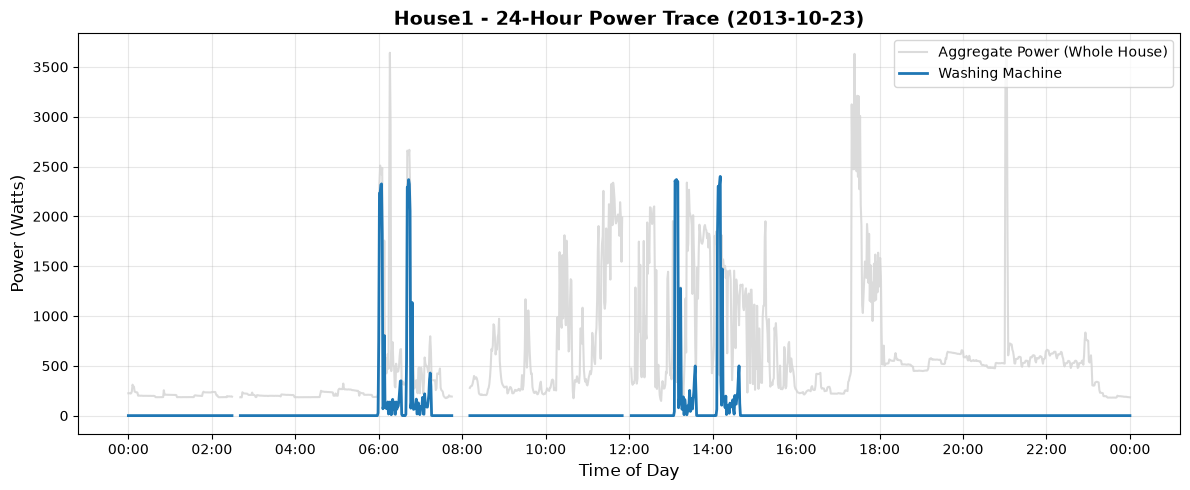

In [38]:
import matplotlib.dates as mdates

# Target House 1
house_name = 'House1'
df = house_data[house_name]

# Find the exact date of the first valid wash cycle
valid_cycles = df[df['Cycle_ID'] > 0]
target_date = valid_cycles.index.min().floor('D')  # Floor to midnight of that day
end_date = target_date + pd.Timedelta(days=1)

# Extract exactly 24 hours of data
day_data = df.loc[target_date:end_date]

# Create the plot
fig, ax = plt.subplots(figsize=(12, 5))

# Plot the total house aggregate power in the background
ax.plot(day_data.index, day_data['Aggregate'], color='lightgray', label='Aggregate Power (Whole House)', alpha=0.8)

# Plot the washing machine power on top
ax.plot(day_data.index, day_data['Washing_Machine'], color='tab:blue', label='Washing Machine', linewidth=2)

# Formatting
ax.set_title(f"{house_name} - 24-Hour Power Trace ({target_date.strftime('%Y-%m-%d')})", fontsize=14, fontweight='bold')
ax.set_ylabel("Power (Watts)", fontsize=12)
ax.set_xlabel("Time of Day", fontsize=12)
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()